# 02. Deep Dive — Numeric


In [21]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [22]:
raw_dir = Path("../data/raw/Dunnhumby")


## 7. Numeric Distribution Summary (df.describe)

Thống kê phân phối các cột số (count, mean, std, min, p25, median, p75, max) tương đương `df.describe()`.

### 7.1. Numeric diagnostics

Thống kê mở rộng dùng toàn bộ giá trị hợp lệ, gồm phân vị, độ lệch, số giá trị bằng 0, âm và dương. Biểu đồ phân phối và đánh giá outlier được tách sang `06_outlier_analysis.ipynb`.


In [23]:
NUMERIC_PLOT_SAMPLE_SIZE = 200_000
NUMERIC_HISTOGRAM_BINS = 60
TRANSACTION_NUMERIC_COLUMNS = [
    "QUANTITY",
    "SALES_VALUE",
    "RETAIL_DISC",
    "COUPON_DISC",
    "COUPON_MATCH_DISC",
]
transaction_detail_columns = [
    "household_key",
    "BASKET_ID",
    "DAY",
    "PRODUCT_ID",
    "STORE_ID",
    *TRANSACTION_NUMERIC_COLUMNS,
]
transaction_detail = pd.read_csv(
    raw_dir / "transaction_data.csv",
    usecols=transaction_detail_columns,
)

numeric_values = {
    ("transaction", column): (
        pd.to_numeric(transaction_detail[column], errors="coerce")
        .dropna()
        .astype("float64")
    )
    for column in TRANSACTION_NUMERIC_COLUMNS
}

numeric_diagnostic_rows = []
for (table_name, column), values in numeric_values.items():
    quantiles = values.quantile([0.01, 0.25, 0.50, 0.75, 0.99])
    n_values = int(values.size)
    n_zero = int(values.eq(0).sum())
    n_negative = int(values.lt(0).sum())
    n_positive = int(values.gt(0).sum())
    numeric_diagnostic_rows.append({
        "table": table_name,
        "column": column,
        "count": n_values,
        "min": float(values.min()),
        "p1": float(quantiles.loc[0.01]),
        "p25": float(quantiles.loc[0.25]),
        "median": float(quantiles.loc[0.50]),
        "p75": float(quantiles.loc[0.75]),
        "p99": float(quantiles.loc[0.99]),
        "max": float(values.max()),
        "mean": float(values.mean()),
        "std": float(values.std()),
        "skew": float(values.skew()),
        "n_zero": n_zero,
        "zero_pct": n_zero / n_values * 100 if n_values else pd.NA,
        "n_negative": n_negative,
        "negative_pct": n_negative / n_values * 100 if n_values else pd.NA,
        "n_positive": n_positive,
        "positive_pct": n_positive / n_values * 100 if n_values else pd.NA,
    })
numeric_diagnostics = pd.DataFrame(numeric_diagnostic_rows)
numeric_diagnostics


,table,column,count,min,p1,p25,median,p75,p99,max,mean,std,skew,n_zero,zero_pct,n_negative,negative_pct,n_positive,positive_pct
0,transaction,QUANTITY,2595732,0.00,1.00,1.00,1.00,1.00,10.0,89638.00,100.428558,1153.436211,13.642979,14466,0.557299,0,0.000000,2581266,99.442701
1,transaction,SALES_VALUE,2595732,0.00,0.20,1.29,2.00,3.49,20.0,840.00,3.104120,4.182274,15.907471,18850,0.726192,0,0.000000,2576882,99.273808
2,transaction,RETAIL_DISC,2595732,-180.00,-4.99,-0.69,-0.01,0.00,0.0,3.99,-0.538705,1.249191,-13.350060,1292670,49.799825,1303026,50.198788,36,0.001387
3,transaction,COUPON_DISC,2595732,-55.93,-0.50,0.00,0.00,0.00,0.0,0.00,-0.016416,0.216841,-44.206637,2559310,98.596851,36422,1.403149,0,0.000000
4,transaction,COUPON_MATCH_DISC,2595732,-7.70,0.00,0.00,0.00,0.00,0.0,0.00,-0.002919,0.039690,-24.434657,2578283,99.327781,17449,0.672219,0,0.000000


### 7.2. Xếp hạng mức độ lệch của biến numeric

`max/p99` được tính trên trị tuyệt đối để so sánh được cả các cột discount âm. Tỷ số cao cho thấy cực trị vượt xa phần đuôi p99; `|skew|` cao cho thấy phân phối bất đối xứng mạnh. Hai biểu đồ giúp ưu tiên biến cần kiểm tra hoặc transform trước.


,variable,max_abs,p99_abs,max_abs_over_p99_abs,skew,abs_skew,tail_rank,skew_rank,priority_rank_mean
0,transaction.COUPON_DISC,55.93,0.50,111.860000,-44.206637,44.206637,2,1,1.5
1,transaction.COUPON_MATCH_DISC,7.70,0.00,NaN,-24.434657,24.434657,<NA>,2,2.0
2,transaction.QUANTITY,89638.00,10.00,8963.800000,13.642979,13.642979,1,4,2.5
3,transaction.SALES_VALUE,840.00,20.00,42.000000,15.907471,15.907471,3,3,3.0
4,transaction.RETAIL_DISC,180.00,4.99,36.072144,-13.350060,13.350060,4,5,4.5


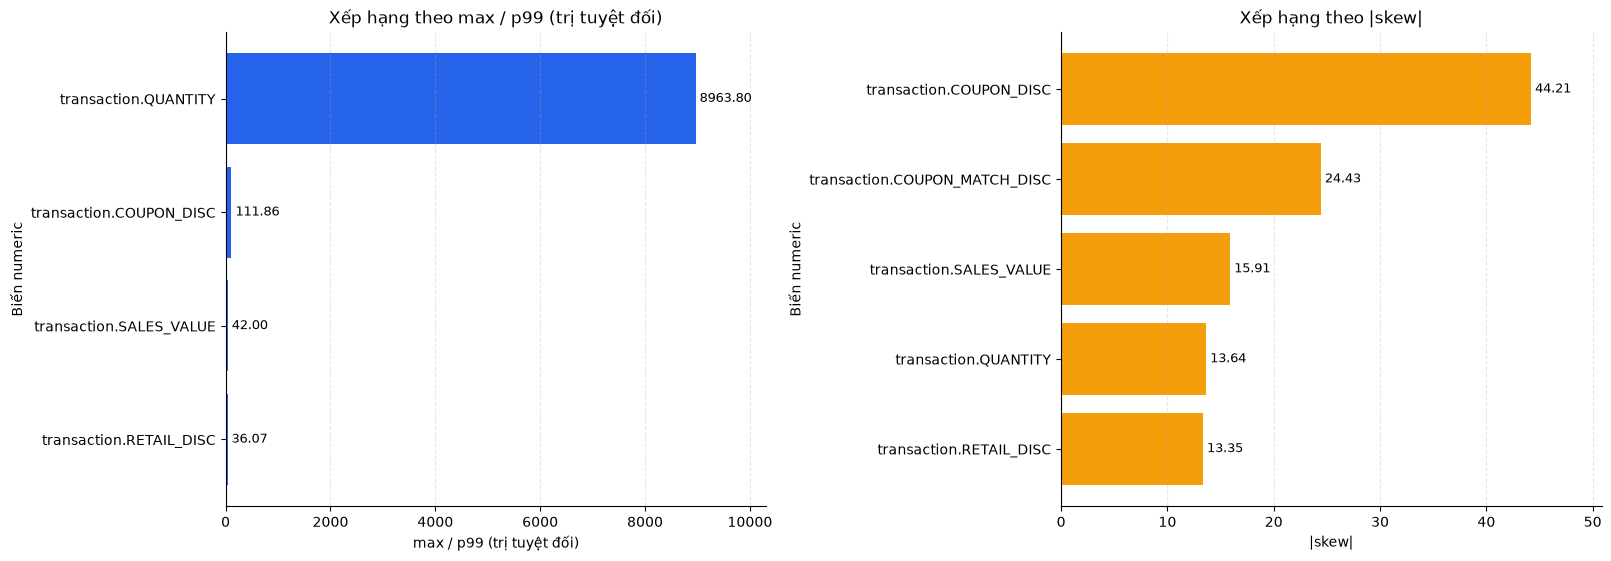

In [24]:
numeric_skew_priority_rows = []
for (table_name, column), values in numeric_values.items():
    absolute_values = values.abs()
    p99_absolute = float(absolute_values.quantile(0.99))
    max_absolute = float(absolute_values.max())
    numeric_skew_priority_rows.append({
        "variable": f"{table_name}.{column}",
        "max_abs": max_absolute,
        "p99_abs": p99_absolute,
        "max_abs_over_p99_abs": (
            max_absolute / p99_absolute if p99_absolute > 0 else np.nan
        ),
        "skew": float(values.skew()),
        "abs_skew": abs(float(values.skew())),
    })

numeric_skew_priority = pd.DataFrame(numeric_skew_priority_rows)
numeric_skew_priority["tail_rank"] = (
    numeric_skew_priority["max_abs_over_p99_abs"]
    .rank(method="min", ascending=False)
    .astype("Int64")
)
numeric_skew_priority["skew_rank"] = (
    numeric_skew_priority["abs_skew"]
    .rank(method="min", ascending=False)
    .astype("Int64")
)
numeric_skew_priority["priority_rank_mean"] = (
    numeric_skew_priority[["tail_rank", "skew_rank"]].mean(axis=1)
)
numeric_skew_priority = numeric_skew_priority.sort_values(
    ["priority_rank_mean", "max_abs_over_p99_abs"], ascending=[True, False]
).reset_index(drop=True)
display(numeric_skew_priority)

numeric_skew_figure, numeric_skew_axes = plt.subplots(
    1, 2, figsize=(16, 5.5), layout="constrained"
)
ranking_plot_specs = [
    ("max_abs_over_p99_abs", "max / p99 (trị tuyệt đối)", "#2563EB"),
    ("abs_skew", "|skew|", "#F59E0B"),
]
for axis, (metric, title, color) in zip(
    numeric_skew_axes, ranking_plot_specs, strict=True
):
    ranked = numeric_skew_priority.sort_values(metric, ascending=True)
    bars = axis.barh(ranked["variable"], ranked[metric], color=color)
    for bar, value in zip(bars, ranked[metric], strict=True):
        axis.text(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2,
            f" {value:.2f}",
            va="center",
            fontsize=9,
        )
    axis.set(title=f"Xếp hạng theo {title}", xlabel=title, ylabel="Biến numeric")
    axis.margins(x=0.15)
    axis.spines[["top", "right"]].set_visible(False)
    axis.grid(axis="x", linestyle="--", alpha=0.3)
plt.show()


***Note***:
- Discount quy ước là <=0, tuy nhiên có 36 retail_discount >0, chiếm tỉ lệ 0.001387%
- Quantity, sale value cũng có 14466 zero, 18850 zero, chiếm tỉ lệ lần lượt là 0.56% và 0.73%
- Những cái có quantity thuộc nhóm lớn nhất là sản phẩm xăng không chì

- retail >0 chỉ chiếm 0.0001387%, không có dòng trùng mà retail >0 để dự đoán trả hàng -> đề xuất bỏ

- Chưa giải thích được ý nghĩa quantity và sale_value đều cùng bằng 0

### 7.3. QUANTITY, fuel và key-frequency diagnostics

Xăng được xác định từ taxonomy sản phẩm (`DEPARTMENT`, `COMMODITY_DESC`, `SUB_COMMODITY_DESC`) bằng các từ khóa gasoline/fuel/diesel/petrol; tuyệt đối không dùng `MANUFACTURER`. Các thống kê và outlier table dùng toàn bộ dữ liệu; biểu đồ có thể dùng mẫu cố định để render ổn định.

In [25]:
FUEL_TAXONOMY_PATTERN = r"\b(?:GASOLINE|MOTOR\s+FUEL|FUEL|DIESEL|PETROL)\b"
product_taxonomy = pd.read_csv(
    raw_dir / "product.csv",
    usecols=[
        "PRODUCT_ID", "MANUFACTURER", "DEPARTMENT",
        "COMMODITY_DESC", "SUB_COMMODITY_DESC",
    ],
)
taxonomy_text = (
    product_taxonomy[["DEPARTMENT", "COMMODITY_DESC", "SUB_COMMODITY_DESC"]]
    .fillna("")
    .astype("string")
    .agg(" | ".join, axis=1)
    .str.upper()
)
product_taxonomy["is_fuel"] = taxonomy_text.str.contains(
    FUEL_TAXONOMY_PATTERN, regex=True, na=False
)
fuel_product_ids = set(
    product_taxonomy.loc[product_taxonomy["is_fuel"], "PRODUCT_ID"]
)
manufacturer_by_product = (
    product_taxonomy
    .drop_duplicates("PRODUCT_ID")
    .set_index("PRODUCT_ID")["MANUFACTURER"]
)

transaction_numeric_columns = TRANSACTION_NUMERIC_COLUMNS
transaction_detail["is_fuel"] = transaction_detail["PRODUCT_ID"].isin(
    fuel_product_ids
)
transaction_detail["MANUFACTURER"] = transaction_detail["PRODUCT_ID"].map(
    manufacturer_by_product
)

#### QUANTITY chuyên biệt

`value_counts` giữ bản chất rời rạc của QUANTITY; log-bin chỉ dùng phần đuôi dương; boxplot dùng các dòng không phải xăng. Bảng phân vị đi đến p99.99 cho cả toàn bộ transaction và phần không phải xăng.

In [26]:
quantity_all = pd.to_numeric(transaction_detail["QUANTITY"], errors="coerce").dropna()
quantity_non_fuel = pd.to_numeric(
    transaction_detail.loc[~transaction_detail["is_fuel"], "QUANTITY"],
    errors="coerce",
).dropna()
quantity_value_counts = (
    quantity_all.value_counts()
    .sort_index()
    .rename("n_rows")
    .to_frame()
)
quantity_value_counts["row_pct"] = (
    quantity_value_counts["n_rows"] / len(quantity_all) * 100
)
quantity_value_counts["cumulative_pct"] = quantity_value_counts["row_pct"].cumsum()
quantity_value_counts.index.name = "QUANTITY"

QUANTITY_QUANTILES = {
    "min": 0.0, "p1": 0.01, "p25": 0.25, "median": 0.50,
    "p75": 0.75, "p90": 0.90, "p95": 0.95, "p99": 0.99,
    "p99.9": 0.999, "p99.99": 0.9999, "max": 1.0,
}
quantity_quantiles = pd.DataFrame({
    "all_transaction": pd.Series({
        label: quantity_all.quantile(probability)
        for label, probability in QUANTITY_QUANTILES.items()
    }),
    "non_fuel": pd.Series({
        label: quantity_non_fuel.quantile(probability)
        for label, probability in QUANTITY_QUANTILES.items()
    }),
})
display(quantity_value_counts.head(30), quantity_quantiles)

,n_rows,row_pct,cumulative_pct
QUANTITY,,,
0,14466,0.557299,0.557299
1,2050967,79.013049,79.570349
2,372373,14.345587,93.915936
3,66962,2.579696,96.495632
4,38667,1.489638,97.985270
5,10918,0.420614,98.405883
6,8981,0.345991,98.751874
7,1379,0.053126,98.805000
8,2531,0.097506,98.902506


,all_transaction,non_fuel
min,0.000,0.0
p1,1.000,1.0
p25,1.000,1.0
median,1.000,1.0
p75,1.000,1.0
p90,2.000,2.0
p95,3.000,3.0
p99,10.000,5.0
p99.9,16943.538,10.0
p99.99,25011.000,23.0


C:\Users\manhh\AppData\Local\Temp\ipykernel_10128\216175233.py:39: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  quantity_axes[2].boxplot(


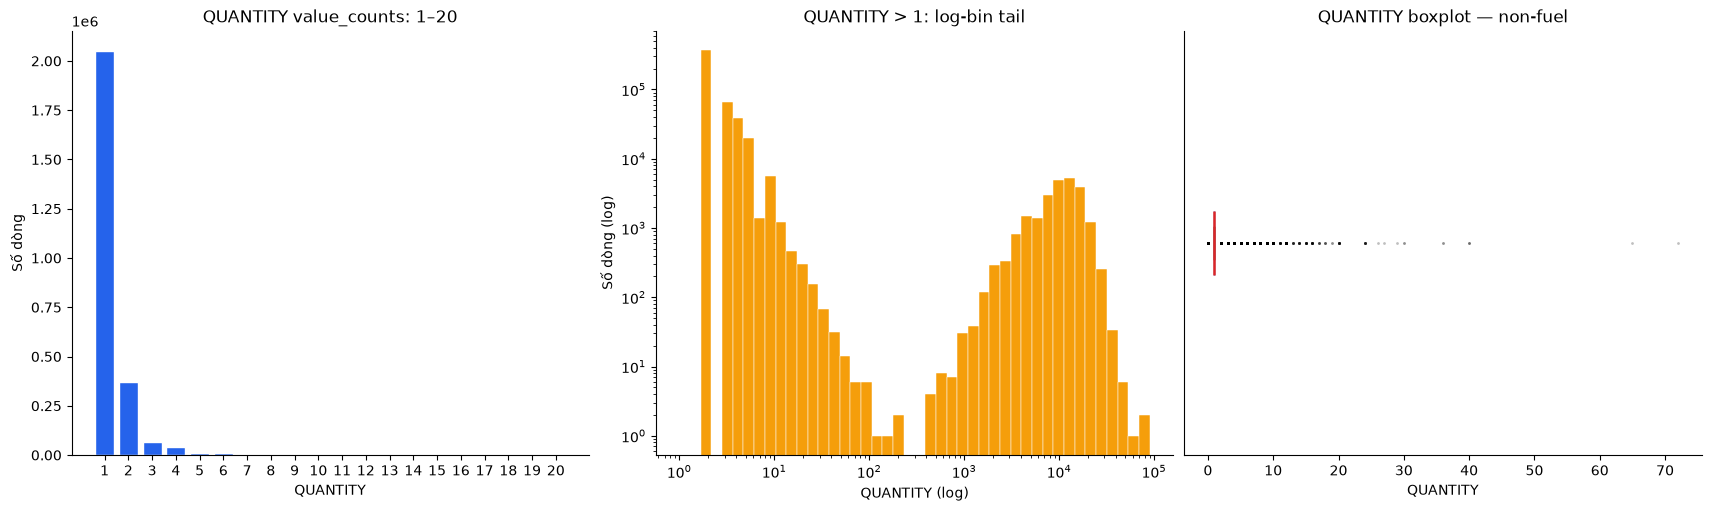

In [27]:
quantity_figure, quantity_axes = plt.subplots(
    1, 3, figsize=(17, 5), layout="constrained"
)
quantity_discrete = (
    quantity_all.loc[quantity_all.ge(1) & quantity_all.mod(1).eq(0)]
    .astype("int64")
    .value_counts()
    .reindex(range(1, 21), fill_value=0)
)
quantity_axes[0].bar(
    quantity_discrete.index, quantity_discrete.values,
    color="#2563EB", edgecolor="white",
)
quantity_axes[0].set_xticks(range(1, 21))
quantity_axes[0].set(
    title="QUANTITY value_counts: 1–20",
    xlabel="QUANTITY", ylabel="Số dòng",
)

quantity_positive_tail = quantity_all.loc[quantity_all.gt(1)]
quantity_tail_max = max(2.0, float(quantity_positive_tail.max()))
quantity_log_bins = np.unique(np.geomspace(1, quantity_tail_max, 45))
quantity_axes[1].hist(
    quantity_positive_tail, bins=quantity_log_bins,
    color="#F59E0B", edgecolor="white", linewidth=0.35,
)
quantity_axes[1].set_xscale("log")
quantity_axes[1].set_yscale("log")
quantity_axes[1].set(
    title="QUANTITY > 1: log-bin tail",
    xlabel="QUANTITY (log)", ylabel="Số dòng (log)",
)

quantity_non_fuel_plot = (
    quantity_non_fuel.sample(NUMERIC_PLOT_SAMPLE_SIZE, random_state=42)
    if len(quantity_non_fuel) > NUMERIC_PLOT_SAMPLE_SIZE
    else quantity_non_fuel
)
quantity_axes[2].boxplot(
    quantity_non_fuel_plot.to_numpy(),
    vert=False, showfliers=True, patch_artist=True,
    flierprops={"marker": ".", "markersize": 2, "alpha": 0.25},
    boxprops={"facecolor": "#93C5FD", "edgecolor": "#2563EB"},
    medianprops={"color": "#DC2626", "linewidth": 1.8},
)
quantity_axes[2].set(
    title="QUANTITY boxplot — non-fuel", xlabel="QUANTITY",
)
quantity_axes[2].set_yticks([])
for axis in quantity_axes:
    axis.spines[["top", "right"]].set_visible(False)
plt.show()

**Kết luận QUANTITY:** QUANTITY ≈ 1 ở gần như mọi dòng và `IQR = 0`. Vì vậy boxplot/IQR gắn cờ mọi giá trị khác 1 như outlier thống kê; không được đồng nhất điều này với lỗi dữ liệu. Phải tách giao dịch xăng và kiểm tra nghiệp vụ trước khi cap hoặc loại.

#### Kiểm tra xăng: SALES_VALUE và giá trên đơn vị

In [28]:
fuel_lines = transaction_detail.loc[transaction_detail["is_fuel"]].copy()
fuel_lines["unit_price"] = (
    pd.to_numeric(fuel_lines["SALES_VALUE"], errors="coerce")
    / pd.to_numeric(fuel_lines["QUANTITY"], errors="coerce").replace(0, np.nan)
)
fuel_coverage = pd.Series({
    "n_fuel_products": len(fuel_product_ids),
    "n_fuel_lines": len(fuel_lines),
    "n_fuel_baskets": fuel_lines["BASKET_ID"].nunique(),
    "n_fuel_households": fuel_lines["household_key"].nunique(),
    "fuel_line_pct": len(fuel_lines) / len(transaction_detail) * 100,
}, name="value").to_frame()
fuel_value_summary = pd.DataFrame({
    "SALES_VALUE": pd.to_numeric(fuel_lines["SALES_VALUE"], errors="coerce"),
    "price_per_unit": fuel_lines["unit_price"],
}).describe(percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]).T
display(fuel_coverage, fuel_value_summary)

,value
n_fuel_products,35.000000
n_fuel_lines,24962.000000
n_fuel_baskets,24952.000000
n_fuel_households,1438.000000
fuel_line_pct,0.961656


,count,mean,std,min,1%,25%,50%,75%,99%,max
SALES_VALUE,24962.0,25.396894,12.711598,0.030000,4.532200,16.140000,24.115000,32.870000,61.1039,250.0
price_per_unit,24962.0,1.189633,4.962020,0.001659,0.001839,0.002108,0.002309,0.002699,25.0000,100.0


### Cần kiểm tra?
- sao số lượng xăng lớn mà unit price lên đến tận 100, trong khi max có 250???

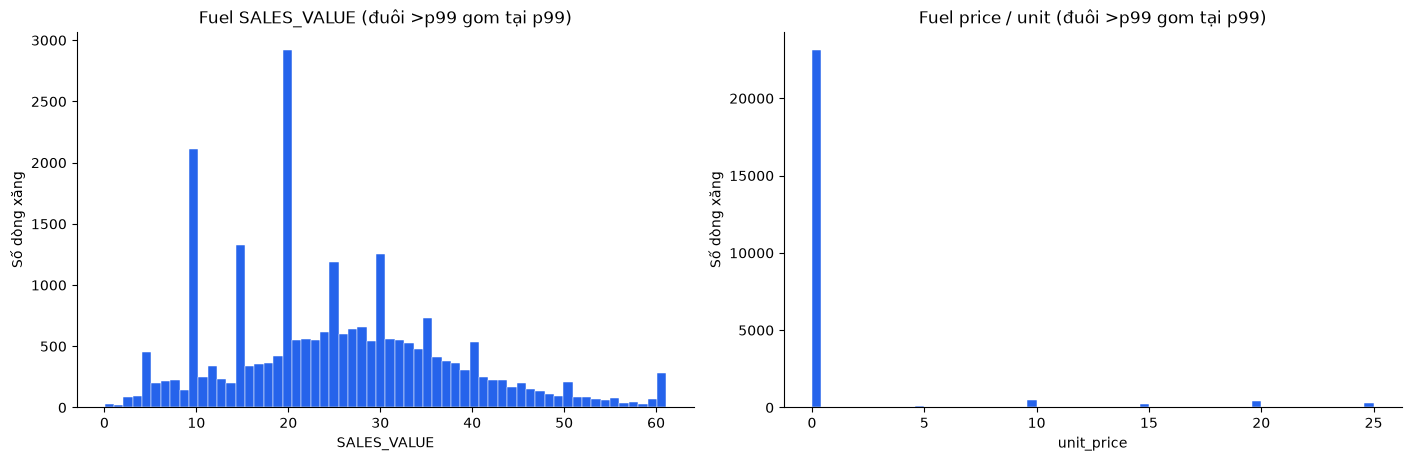

In [29]:
fuel_value_figure, fuel_value_axes = plt.subplots(
    1, 2, figsize=(14, 4.5), layout="constrained"
)
for axis, column, title in (
    (fuel_value_axes[0], "SALES_VALUE", "Fuel SALES_VALUE"),
    (fuel_value_axes[1], "unit_price", "Fuel price / unit"),
):
    values = pd.to_numeric(fuel_lines[column], errors="coerce").dropna()
    plot_limit = float(values.quantile(0.99))
    axis.hist(
        values.clip(upper=plot_limit), bins=60,
        color="#2563EB", edgecolor="white", linewidth=0.35,
    )
    axis.set(
        title=f"{title} (đuôi >p99 gom tại p99)",
        xlabel=column, ylabel="Số dòng xăng",
    )
    axis.spines[["top", "right"]].set_visible(False)
plt.show()

In [30]:
CATEGORY_COLUMNS = ["DEPARTMENT", "COMMODITY_DESC", "SUB_COMMODITY_DESC"]
category_lookup = product_taxonomy.drop_duplicates("PRODUCT_ID").set_index("PRODUCT_ID")
for category_column in CATEGORY_COLUMNS:
    transaction_detail[category_column] = (
        transaction_detail["PRODUCT_ID"]
        .map(category_lookup[category_column])
        .fillna("<MISSING>")
        .astype("category")
    )


### 7.6. Taxonomy của top 0,01% QUANTITY

Các dòng có `QUANTITY ≥ p99.99` được gom theo `DEPARTMENT × COMMODITY_DESC`. Ngưỡng giữ toàn bộ ties nên số dòng có thể lớn hơn đúng 0,01%. Cột `fuel_line_pct` dùng cờ xăng xác định từ taxonomy; `MANUFACTURER` không tham gia phép xác định.

In [31]:
quantity_numeric = pd.to_numeric(transaction_detail["QUANTITY"], errors="coerce")
quantity_p9999 = float(quantity_numeric.quantile(0.9999))
largest_quantity_lines = transaction_detail.loc[
    quantity_numeric.ge(quantity_p9999),
    [
        "PRODUCT_ID", "BASKET_ID", "household_key", "QUANTITY",
        "SALES_VALUE", "DEPARTMENT", "COMMODITY_DESC",
        "SUB_COMMODITY_DESC", "is_fuel",
    ],
].copy()
largest_quantity_taxonomy = (
    largest_quantity_lines
    .groupby(["DEPARTMENT", "COMMODITY_DESC"], observed=True, dropna=False)
    .agg(
        n_lines=("PRODUCT_ID", "size"),
        n_products=("PRODUCT_ID", "nunique"),
        n_baskets=("BASKET_ID", "nunique"),
        n_households=("household_key", "nunique"),
        min_quantity=("QUANTITY", "min"),
        median_quantity=("QUANTITY", "median"),
        max_quantity=("QUANTITY", "max"),
        median_sales_value=("SALES_VALUE", "median"),
        fuel_lines=("is_fuel", "sum"),
    )
    .reset_index()
)
largest_quantity_taxonomy["line_pct_within_top_0_01pct"] = (
    largest_quantity_taxonomy["n_lines"] / len(largest_quantity_lines) * 100
)
largest_quantity_taxonomy["fuel_line_pct"] = (
    largest_quantity_taxonomy["fuel_lines"]
    / largest_quantity_taxonomy["n_lines"] * 100
)
largest_quantity_taxonomy = largest_quantity_taxonomy.sort_values(
    ["n_lines", "max_quantity"], ascending=[False, False]
)
largest_quantity_overview = pd.Series({
    "p99.99_quantity_threshold": quantity_p9999,
    "n_lines_at_or_above_threshold": len(largest_quantity_lines),
    "actual_line_pct": len(largest_quantity_lines) / quantity_numeric.notna().sum() * 100,
    "fuel_line_pct": largest_quantity_lines["is_fuel"].mean() * 100,
}, name="value").to_frame()
display(largest_quantity_overview, largest_quantity_taxonomy)

,value
p99.99_quantity_threshold,25011.000000
n_lines_at_or_above_threshold,261.000000
actual_line_pct,0.010055
fuel_line_pct,100.000000


,DEPARTMENT,COMMODITY_DESC,n_lines,n_products,n_baskets,n_households,min_quantity,median_quantity,max_quantity,median_sales_value,fuel_lines,line_pct_within_top_0_01pct,fuel_line_pct
0,KIOSK-GAS,COUPON/MISC ITEMS,204,4,204,66,25011,27580.0,89638,63.93,204,78.160920,100.0
2,MISC SALES TRAN,COUPON/MISC ITEMS,56,4,56,21,25012,27597.5,85055,75.00,56,21.455939,100.0
1,KIOSK-GAS,FUEL,1,1,1,1,30080,30080.0,30080,86.01,1,0.383142,100.0


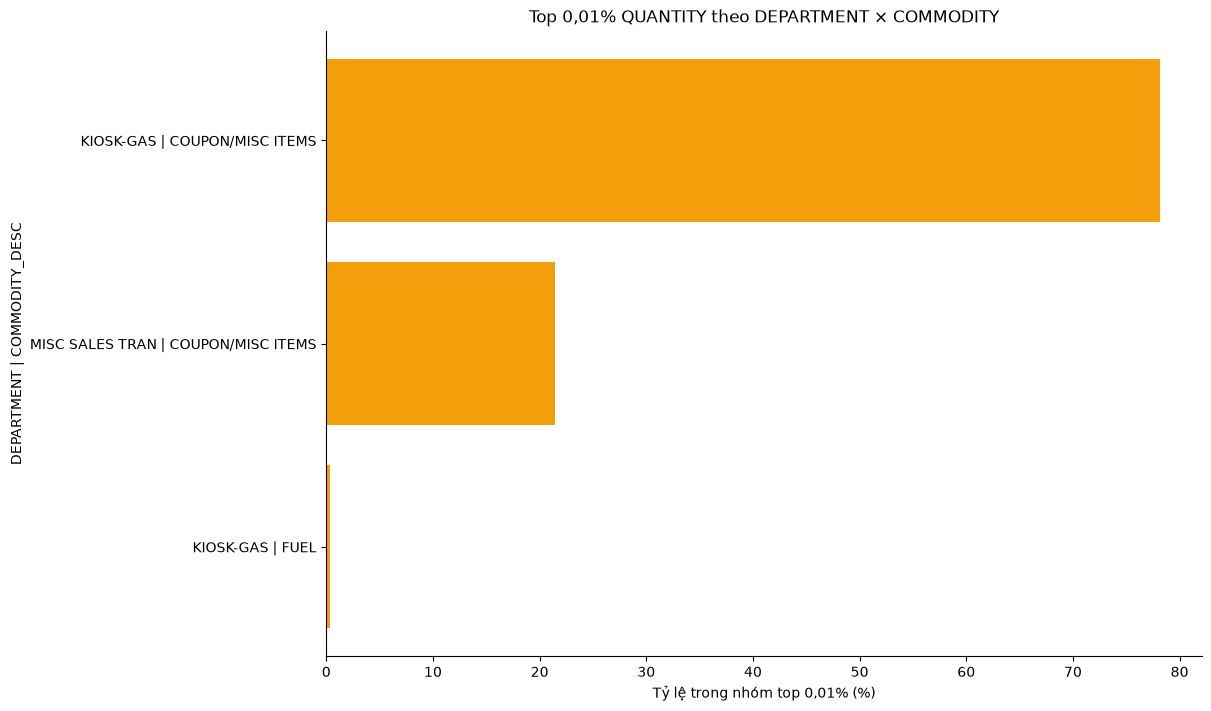

In [32]:
largest_quantity_top = largest_quantity_taxonomy.head(20).sort_values("n_lines")
largest_quantity_labels = (
    largest_quantity_top["DEPARTMENT"].astype("string")
    + " | "
    + largest_quantity_top["COMMODITY_DESC"].astype("string")
)
largest_quantity_figure, largest_quantity_axis = plt.subplots(
    figsize=(12, 7), layout="constrained"
)
largest_quantity_axis.barh(
    largest_quantity_labels,
    largest_quantity_top["line_pct_within_top_0_01pct"],
    color=[
        "#F59E0B" if value > 0 else "#2563EB"
        for value in largest_quantity_top["fuel_lines"]
    ],
)
largest_quantity_axis.set(
    title="Top 0,01% QUANTITY theo DEPARTMENT × COMMODITY",
    xlabel="Tỷ lệ trong nhóm top 0,01% (%)",
    ylabel="DEPARTMENT | COMMODITY_DESC",
)
largest_quantity_axis.spines[["top", "right"]].set_visible(False)
plt.show()

### 7.7. Top QUANTITY theo nhóm sản phẩm

Xếp hạng tổng `QUANTITY` theo `DEPARTMENT`, `COMMODITY_DESC` và `DEPARTMENT × COMMODITY_DESC`. Bảng hiển thị top 10 và top 20; biểu đồ dùng horizontal bar chart để đọc nhãn dài.


In [33]:
QUANTITY_GROUP_SPECS = [
    ("DEPARTMENT", ["DEPARTMENT"]),
    ("COMMODITY_DESC", ["COMMODITY_DESC"]),
    ("DEPARTMENT × COMMODITY_DESC", ["DEPARTMENT", "COMMODITY_DESC"]),
]

quantity_group_profiles = {}
for group_name, group_columns in QUANTITY_GROUP_SPECS:
    profile = (
        transaction_detail
        .groupby(group_columns, observed=True, dropna=False)
        .agg(
            total_quantity=("QUANTITY", "sum"),
            median_quantity=("QUANTITY", "median"),
            n_lines=("PRODUCT_ID", "size"),
            n_products=("PRODUCT_ID", "nunique"),
            n_households=("household_key", "nunique"),
        )
        .reset_index()
    )
    profile["group_label"] = (
        profile[group_columns].astype("string").agg(" × ".join, axis=1)
    )
    profile = profile.sort_values(
        ["total_quantity", "n_lines"], ascending=[False, False]
    ).reset_index(drop=True)
    profile["quantity_pct"] = (
        profile["total_quantity"] / profile["total_quantity"].sum() * 100
    )
    profile["cumulative_quantity_pct"] = profile["quantity_pct"].cumsum()
    quantity_group_profiles[group_name] = profile

for group_name, profile in quantity_group_profiles.items():
    print(f"=== {group_name}: TOP 10 THEO TỔNG QUANTITY ===")
    display(profile.head(10))
    print(f"=== {group_name}: TOP 20 THEO TỔNG QUANTITY ===")
    display(profile.head(20))


=== DEPARTMENT: TOP 10 THEO TỔNG QUANTITY ===


,DEPARTMENT,total_quantity,median_quantity,n_lines,n_products,n_households,group_label,quantity_pct,cumulative_quantity_pct
0,KIOSK-GAS,221254887,10005.0,22059,16,1371,KIOSK-GAS,84.874219,84.874219
1,MISC SALES TRAN,36080860,2.0,6050,88,1393,MISC SALES TRAN,13.840756,98.714975
2,GROCERY,2194762,1.0,1646076,39019,2500,GROCERY,0.841919,99.556894
3,DRUG GM,353844,1.0,277232,31523,2491,DRUG GM,0.135736,99.692630
4,PRODUCE,319993,1.0,257290,3117,2456,PRODUCE,0.122751,99.815381
5,MEAT-PCKGD,148148,1.0,111957,2427,2392,MEAT-PCKGD,0.056830,99.872211
6,MEAT,119113,1.0,88416,2544,2351,MEAT,0.045692,99.917903
7,DELI,67026,1.0,62787,2354,2248,DELI,0.025711,99.943614
8,PASTRY,49820,1.0,38179,2149,2281,PASTRY,0.019111,99.962726
9,NUTRITION,43253,1.0,32164,2913,1719,NUTRITION,0.016592,99.979318


=== DEPARTMENT: TOP 20 THEO TỔNG QUANTITY ===


,DEPARTMENT,total_quantity,median_quantity,n_lines,n_products,n_households,group_label,quantity_pct,cumulative_quantity_pct
0,KIOSK-GAS,221254887,10005.0,22059,16,1371,KIOSK-GAS,84.874219,84.874219
1,MISC SALES TRAN,36080860,2.0,6050,88,1393,MISC SALES TRAN,13.840756,98.714975
2,GROCERY,2194762,1.0,1646076,39019,2500,GROCERY,0.841919,99.556894
3,DRUG GM,353844,1.0,277232,31523,2491,DRUG GM,0.135736,99.692630
4,PRODUCE,319993,1.0,257290,3117,2456,PRODUCE,0.122751,99.815381
5,MEAT-PCKGD,148148,1.0,111957,2427,2392,MEAT-PCKGD,0.056830,99.872211
6,MEAT,119113,1.0,88416,2544,2351,MEAT,0.045692,99.917903
7,DELI,67026,1.0,62787,2354,2248,DELI,0.025711,99.943614
8,PASTRY,49820,1.0,38179,2149,2281,PASTRY,0.019111,99.962726
9,NUTRITION,43253,1.0,32164,2913,1719,NUTRITION,0.016592,99.979318


=== COMMODITY_DESC: TOP 10 THEO TỔNG QUANTITY ===


,COMMODITY_DESC,total_quantity,median_quantity,n_lines,n_products,n_households,group_label,quantity_pct,cumulative_quantity_pct
0,COUPON/MISC ITEMS,257218037,9526.0,27849,128,1985,COUPON/MISC ITEMS,98.669821,98.669821
1,SOFT DRINKS,160637,1.0,117532,1704,2405,SOFT DRINKS,0.061621,98.731442
2,FUEL,119617,1.0,1788,6,346,FUEL,0.045886,98.777328
3,FLUID MILK PRODUCTS,116192,1.0,85630,455,2421,FLUID MILK PRODUCTS,0.044572,98.821899
4,BAKED BREAD/BUNS/ROLLS,99713,1.0,83232,1169,2400,BAKED BREAD/BUNS/ROLLS,0.038250,98.860150
5,CHEESE,96402,1.0,74885,1096,2350,CHEESE,0.036980,98.897130
6,SOUP,85689,1.0,46135,978,2195,SOUP,0.032871,98.930000
7,BAG SNACKS,80824,1.0,67190,1523,2348,BAG SNACKS,0.031004,98.961005
8,FRZN MEAT/MEAT DINNERS,79391,1.0,56064,1268,2069,FRZN MEAT/MEAT DINNERS,0.030455,98.991460
9,VEGETABLES - SHELF STABLE,77503,2.0,41612,831,2138,VEGETABLES - SHELF STABLE,0.029730,99.021190


... (2 outputs left out)

=== DEPARTMENT × COMMODITY_DESC: TOP 10 THEO TỔNG QUANTITY ===


,DEPARTMENT,COMMODITY_DESC,total_quantity,median_quantity,n_lines,n_products,n_households,group_label,quantity_pct,cumulative_quantity_pct
0,KIOSK-GAS,COUPON/MISC ITEMS,221135270,10548.0,20271,10,1359,KIOSK-GAS × COUPON/MISC ITEMS,84.828334,84.828334
1,MISC SALES TRAN,COUPON/MISC ITEMS,36080860,2.0,6050,88,1393,MISC SALES TRAN × COUPON/MISC ITEMS,13.840756,98.669090
2,GROCERY,SOFT DRINKS,160637,1.0,117532,1704,2405,GROCERY × SOFT DRINKS,0.061621,98.730711
3,KIOSK-GAS,FUEL,119617,1.0,1788,6,346,KIOSK-GAS × FUEL,0.045886,98.776596
4,GROCERY,FLUID MILK PRODUCTS,116192,1.0,85630,455,2421,GROCERY × FLUID MILK PRODUCTS,0.044572,98.821168
5,GROCERY,BAKED BREAD/BUNS/ROLLS,99713,1.0,83232,1169,2400,GROCERY × BAKED BREAD/BUNS/ROLLS,0.038250,98.859418
6,GROCERY,CHEESE,96402,1.0,74885,1096,2350,GROCERY × CHEESE,0.036980,98.896398
7,GROCERY,SOUP,85009,1.0,45578,847,2188,GROCERY × SOUP,0.032610,98.929008
8,GROCERY,BAG SNACKS,80824,1.0,67190,1523,2348,GROCERY × BAG SNACKS,0.031004,98.960012
9,GROCERY,FRZN MEAT/MEAT DINNERS,79391,1.0,56064,1268,2069,GROCERY × FRZN MEAT/MEAT DINNERS,0.030455,98.990467


=== DEPARTMENT × COMMODITY_DESC: TOP 20 THEO TỔNG QUANTITY ===


,DEPARTMENT,COMMODITY_DESC,total_quantity,median_quantity,n_lines,n_products,n_households,group_label,quantity_pct,cumulative_quantity_pct
0,KIOSK-GAS,COUPON/MISC ITEMS,221135270,10548.0,20271,10,1359,KIOSK-GAS × COUPON/MISC ITEMS,84.828334,84.828334
1,MISC SALES TRAN,COUPON/MISC ITEMS,36080860,2.0,6050,88,1393,MISC SALES TRAN × COUPON/MISC ITEMS,13.840756,98.669090
2,GROCERY,SOFT DRINKS,160637,1.0,117532,1704,2405,GROCERY × SOFT DRINKS,0.061621,98.730711
3,KIOSK-GAS,FUEL,119617,1.0,1788,6,346,KIOSK-GAS × FUEL,0.045886,98.776596
4,GROCERY,FLUID MILK PRODUCTS,116192,1.0,85630,455,2421,GROCERY × FLUID MILK PRODUCTS,0.044572,98.821168
5,GROCERY,BAKED BREAD/BUNS/ROLLS,99713,1.0,83232,1169,2400,GROCERY × BAKED BREAD/BUNS/ROLLS,0.038250,98.859418
6,GROCERY,CHEESE,96402,1.0,74885,1096,2350,GROCERY × CHEESE,0.036980,98.896398
7,GROCERY,SOUP,85009,1.0,45578,847,2188,GROCERY × SOUP,0.032610,98.929008
8,GROCERY,BAG SNACKS,80824,1.0,67190,1523,2348,GROCERY × BAG SNACKS,0.031004,98.960012
9,GROCERY,FRZN MEAT/MEAT DINNERS,79391,1.0,56064,1268,2069,GROCERY × FRZN MEAT/MEAT DINNERS,0.030455,98.990467


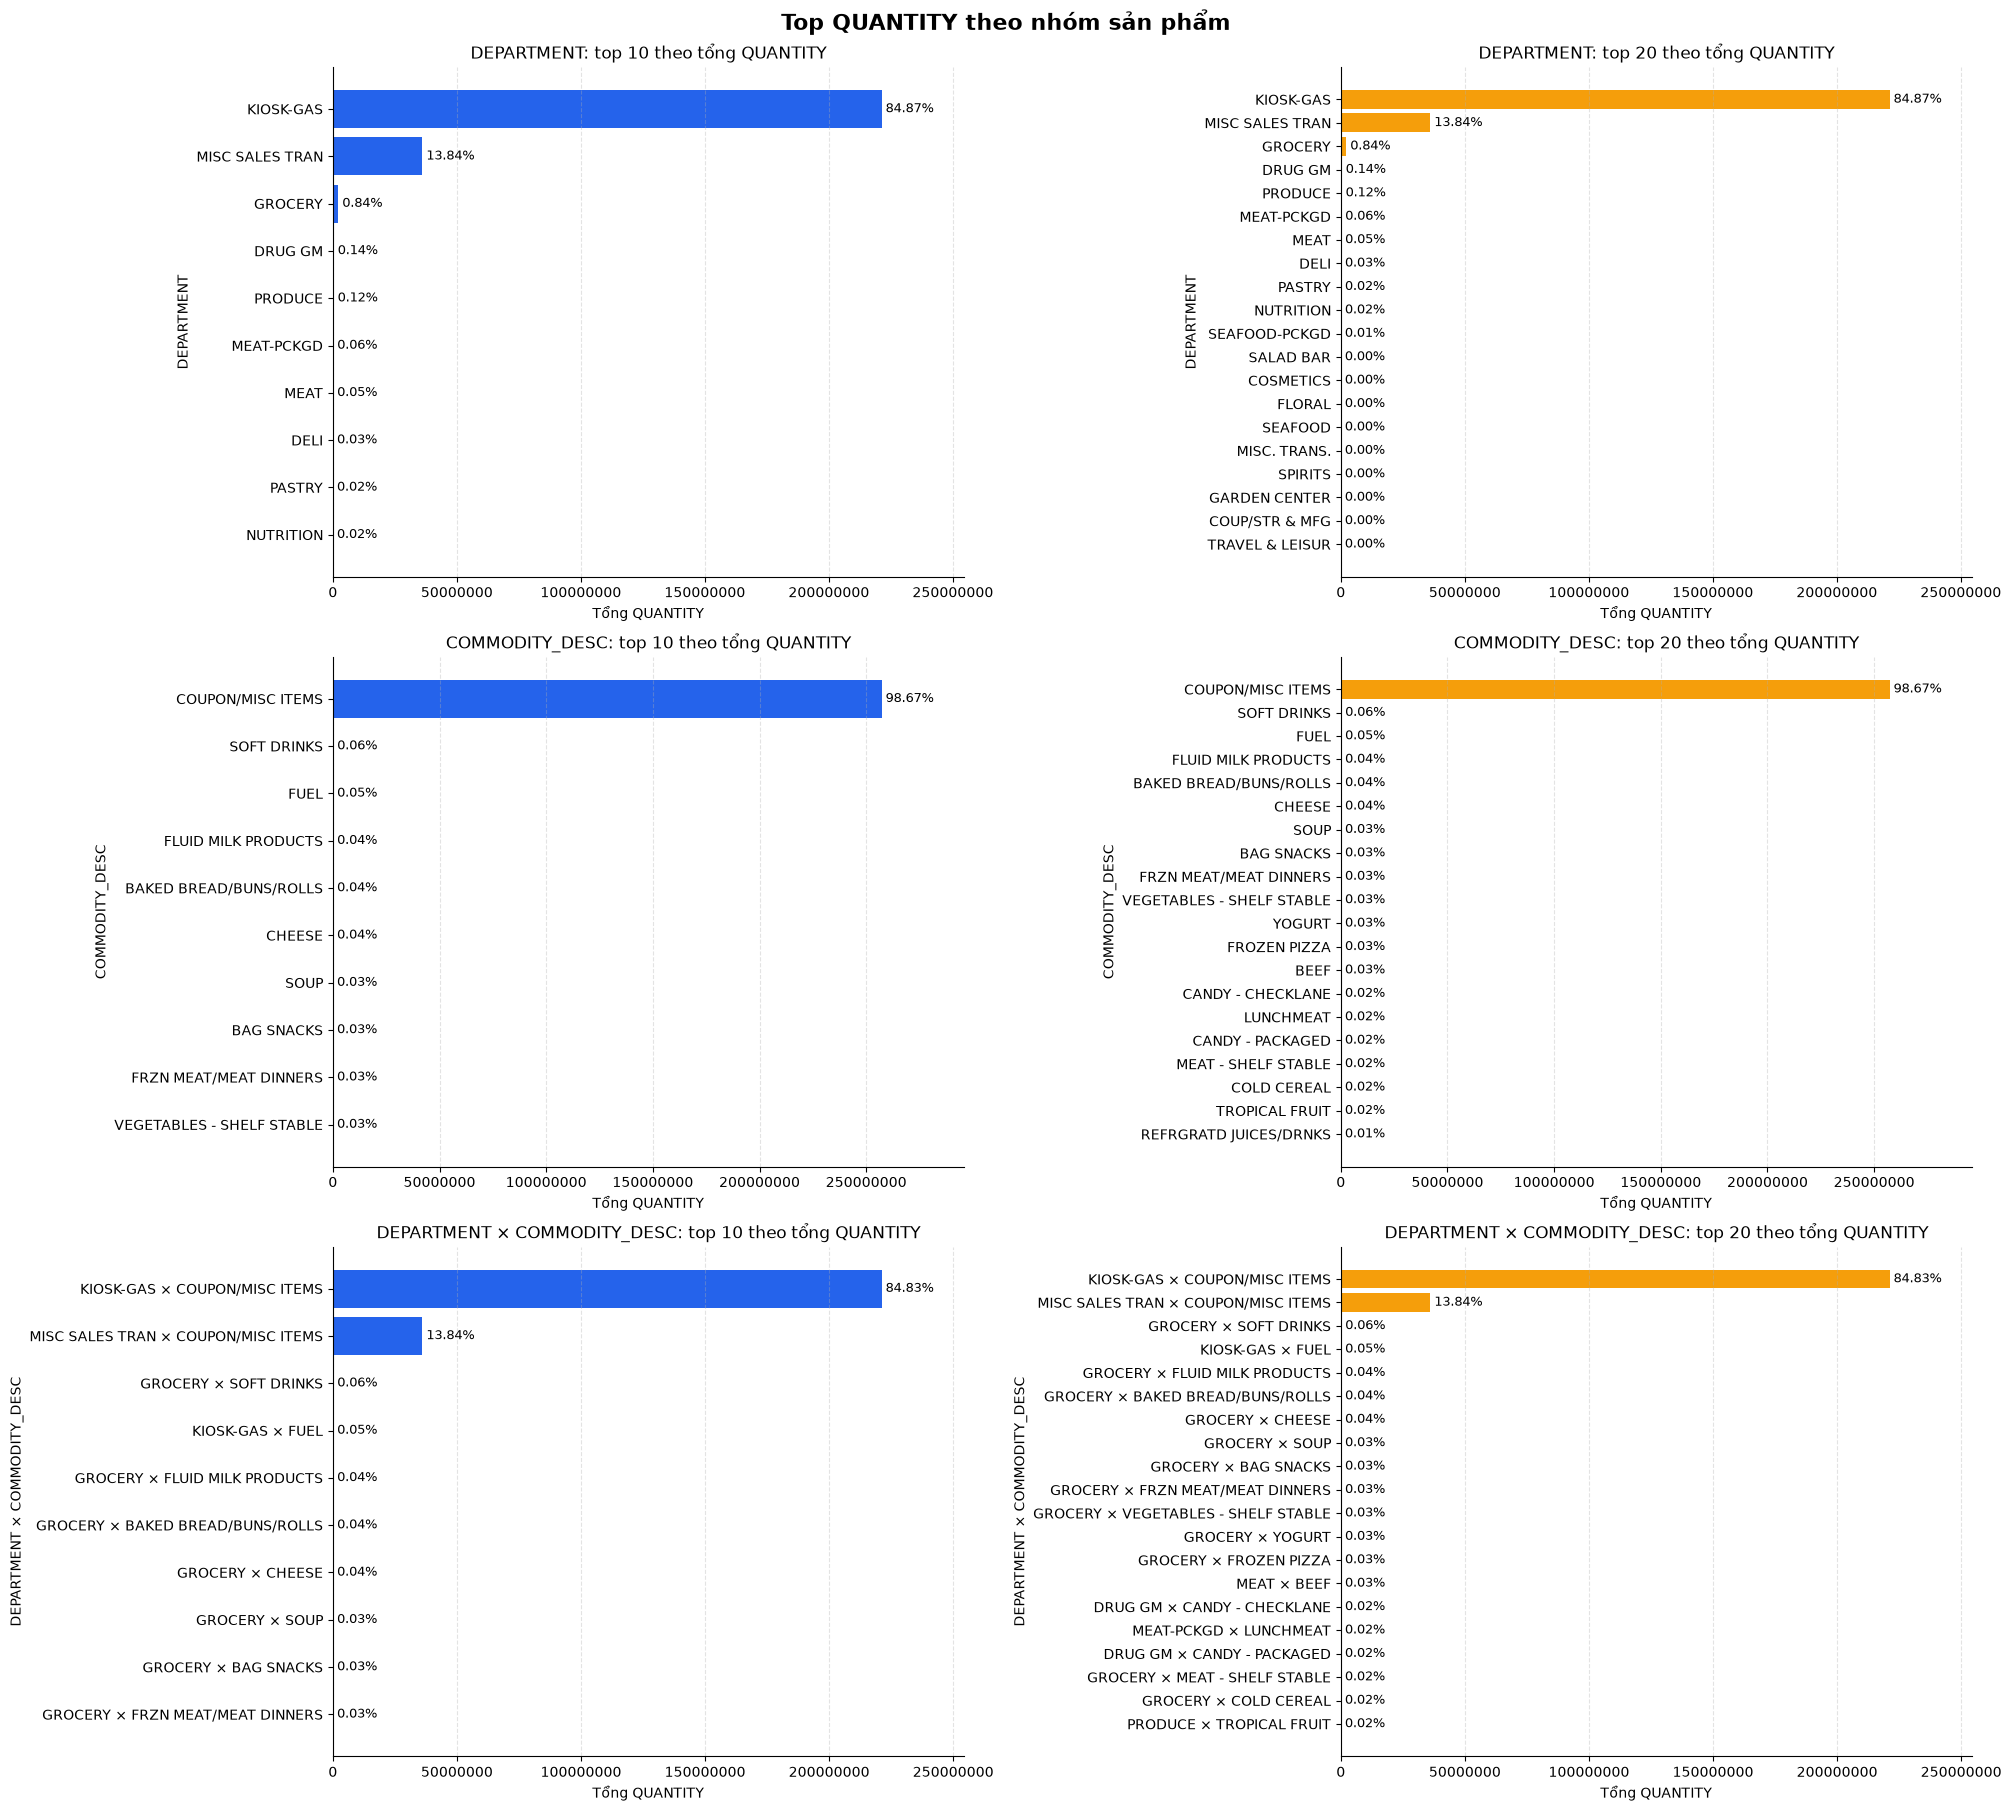

In [34]:
quantity_group_figure, quantity_group_axes = plt.subplots(
    len(QUANTITY_GROUP_SPECS),
    2,
    figsize=(20, 6 * len(QUANTITY_GROUP_SPECS)),
    layout="constrained",
)
for row_index, (group_name, _) in enumerate(QUANTITY_GROUP_SPECS):
    profile = quantity_group_profiles[group_name]
    for column_index, top_n in enumerate((10, 20)):
        axis = quantity_group_axes[row_index, column_index]
        top_profile = profile.head(top_n).sort_values("total_quantity")
        bars = axis.barh(
            top_profile["group_label"],
            top_profile["total_quantity"],
            color="#2563EB" if top_n == 10 else "#F59E0B",
        )
        for bar, quantity_pct in zip(
            bars, top_profile["quantity_pct"], strict=True
        ):
            axis.text(
                bar.get_width(),
                bar.get_y() + bar.get_height() / 2,
                f" {quantity_pct:.2f}%",
                va="center",
                fontsize=9,
            )
        axis.set(
            title=f"{group_name}: top {top_n} theo tổng QUANTITY",
            xlabel="Tổng QUANTITY",
            ylabel=group_name,
        )
        axis.ticklabel_format(axis="x", style="plain")
        axis.margins(x=0.15)
        axis.spines[["top", "right"]].set_visible(False)
        axis.grid(axis="x", linestyle="--", alpha=0.35)
quantity_group_figure.suptitle(
    "Top QUANTITY theo nhóm sản phẩm", fontsize=16, fontweight="bold"
)
plt.show()
